# Machine Learning — Notebook 12
## K-Nearest Neighbors (KNN) & Support Vector Machines (SVM)

**Program:** Data Science & Artificial Intelligence  
**Stage:** Machine Learning  
**Business case:** AdventureWorks — E-commerce Return Risk  
**Level:** Applied Machine Learning

---

### Learning outcomes

By the end of this notebook, you will be able to:

- Explain how KNN classifies a new observation using nearby training examples.
- Calculate and compare common distance measures.
- Explain why feature scaling is essential for distance-based models.
- Train and tune a KNN classifier using a leakage-safe pipeline.
- Explain support vectors, margins, linear SVMs, and kernel-based classification.
- Understand the roles of `C`, `gamma`, and kernel choice.
- Compare KNN and SVM using cross-validation and a held-out test set.
- Select a model based on business needs, not accuracy alone.

### Business context

AdventureWorks wants to identify orders that are at **high risk of being returned**. The operations team can review a limited number of orders before delivery. A useful model should identify risky orders early enough for the team to take action.

We will use a deterministic synthetic dataset designed for teaching. The records represent order-level information. They do not describe real customers or actual company transactions.

### Notebook workflow

1. Understand the prediction task and prepare the data.
2. Build a KNN classifier and study its key parameters.
3. Build SVM classifiers and understand their decision boundaries.
4. Tune both algorithms using cross-validation.
5. compare their test performance and operational trade-offs.
6. Complete an applied mini project.

## 1. Set up the environment

We will use pandas to inspect the dataset, NumPy for reproducible data generation, Matplotlib and Seaborn for visual analysis, and scikit-learn to build the models.

The code uses standard scikit-learn estimators and pipelines. If you are working in a fresh environment, install the required packages first.

In [1]:
# Uncomment this line only if the required packages are not installed.
# %pip install -q numpy pandas matplotlib seaborn scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

## 2. Define the business problem

### What are we predicting?

The target is `return_risk`:

- `1`: the order is classified as high risk of being returned.
- `0`: the order is not classified as high risk.

This is a **binary classification** problem because the target has two possible classes.

### Prediction timing

Assume the features are available when the order is prepared for dispatch. The model must not use information that becomes available only after the return decision. This timing rule helps prevent target leakage.

### Features

| Feature | Meaning | Example unit |
|---|---|---|
| `order_value` | Total value of the order | Currency units |
| `items_count` | Number of items in the order | Items |
| `customer_orders` | Previous completed orders by the customer | Orders |
| `discount_pct` | Discount applied to the order | Percentage |
| `delivery_delay_days` | Expected delivery delay relative to promise | Days |
| `days_since_last_order` | Days since the customer's previous order | Days |
| `product_risk_score` | Historical category-level return tendency | 0–1 score |

The values are synthetic and created for instruction. The target is generated from a risk process with both linear and non-linear effects, so the algorithms have patterns to learn.

## 3. Create a reproducible AdventureWorks dataset

We use a fixed random seed so that the same notebook produces the same dataset each time. The target is generated from a risk score with several interacting effects and random variation. This is a teaching simulation, not a claim about real return behaviour.

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
n_samples = 1800

order_value = np.clip(rng.gamma(shape=2.4, scale=55, size=n_samples), 12, 650)
items_count = rng.integers(1, 8, size=n_samples)
customer_orders = np.clip(rng.poisson(lam=5, size=n_samples), 0, 35)
discount_pct = rng.choice([0, 5, 10, 15, 20, 25, 30], size=n_samples,
                          p=[0.22, 0.12, 0.20, 0.16, 0.14, 0.10, 0.06])
delivery_delay_days = np.clip(rng.normal(loc=1.4, scale=2.1, size=n_samples), -3, 9)
days_since_last_order = np.clip(rng.gamma(shape=2.0, scale=18, size=n_samples), 0, 180)
product_risk_score = rng.beta(a=2.2, b=4.0, size=n_samples)

# Build a risk score with non-linear and interaction effects.
risk_score = (
    -2.15
    + 0.0022 * order_value
    + 0.16 * items_count
    - 0.075 * customer_orders
    + 0.035 * discount_pct
    + 0.34 * np.maximum(delivery_delay_days, 0)
    + 0.006 * days_since_last_order
    + 2.0 * product_risk_score
    + 0.018 * discount_pct * product_risk_score
    - 0.012 * customer_orders * product_risk_score
)

risk_probability = 1 / (1 + np.exp(-risk_score))
return_risk = rng.binomial(1, risk_probability)

orders = pd.DataFrame({
    "order_value": order_value.round(2),
    "items_count": items_count,
    "customer_orders": customer_orders,
    "discount_pct": discount_pct,
    "delivery_delay_days": delivery_delay_days.round(1),
    "days_since_last_order": days_since_last_order.round(1),
    "product_risk_score": product_risk_score.round(3),
    "return_risk": return_risk
})

orders.head()

,order_value,items_count,customer_orders,discount_pct,delivery_delay_days,days_since_last_order,product_risk_score,return_risk
0,139.50,3,6,10,4.2,50.3,0.545,1
1,183.93,5,7,20,-1.3,33.6,0.130,0
2,124.08,7,7,5,3.8,32.3,0.062,0
3,112.34,5,5,0,4.8,16.7,0.469,1
4,198.34,4,4,15,0.9,6.1,0.394,1


In [4]:
print(f"Dataset shape: {orders.shape}")
print(f"High-risk rate: {orders['return_risk'].mean():.1%}")
print("\\nTarget distribution:")
print(orders["return_risk"].value_counts().sort_index())

Dataset shape: (1800, 8)
High-risk rate: 58.6%
\nTarget distribution:
return_risk
0     746
1    1054
Name: count, dtype: int64


### Inspect the data

Before fitting a model, check the shape, data types, missing values, and target distribution. This is a basic quality check, not a complete data-cleaning workflow.

In [5]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_value            1800 non-null   float64
 1   items_count            1800 non-null   int64  
 2   customer_orders        1800 non-null   int64  
 3   discount_pct           1800 non-null   int64  
 4   delivery_delay_days    1800 non-null   float64
 5   days_since_last_order  1800 non-null   float64
 6   product_risk_score     1800 non-null   float64
 7   return_risk            1800 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 112.6 KB


In [6]:
orders.describe().T

,count,mean,std,min,25%,50%,75%,max
order_value,1800.0,133.244778,86.640662,12.000,70.3575,117.800,175.73500,595.790
items_count,1800.0,3.995556,1.983249,1.000,2.0000,4.000,6.00000,7.000
customer_orders,1800.0,5.007778,2.277557,0.000,3.0000,5.000,6.00000,14.000
discount_pct,1800.0,12.333333,9.498252,0.000,5.0000,10.000,20.00000,30.000
delivery_delay_days,1800.0,1.513556,2.044128,-3.000,0.1000,1.500,2.90000,8.000
days_since_last_order,1800.0,37.507778,26.224613,0.600,17.5000,32.200,51.02500,180.000
product_risk_score,1800.0,0.352914,0.178083,0.016,0.2130,0.337,0.48025,0.909
return_risk,1800.0,0.585556,0.492763,0.000,0.0000,1.000,1.00000,1.000


In [7]:
orders.isna().sum()

order_value              0
items_count              0
customer_orders          0
discount_pct             0
delivery_delay_days      0
days_since_last_order    0
product_risk_score       0
return_risk              0
dtype: int64

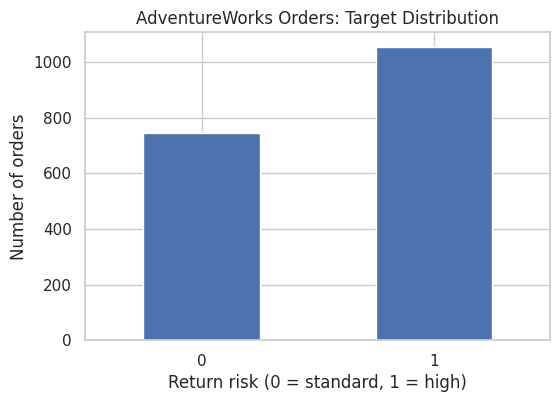

In [8]:
plt.figure(figsize=(6, 4))
orders["return_risk"].value_counts().sort_index().plot(kind="bar", rot=0)
plt.title("AdventureWorks Orders: Target Distribution")
plt.xlabel("Return risk (0 = standard, 1 = high)")
plt.ylabel("Number of orders")
plt.show()

### Interpret the target distribution

The target is not expected to be perfectly balanced. A model that always predicts the majority class may achieve a reasonable-looking accuracy while failing to identify high-risk orders.

For this reason, later we will review precision, recall, F1-score, and ROC-AUC rather than relying on accuracy alone.

## 4. Separate features, target, and test data

`X` contains the input features and `y` contains the target label. We reserve a test set before model tuning. The test set is kept separate until the final comparison.

We use `stratify=y` so that the proportion of high-risk and standard-risk orders remains similar in the training and test sets.

In [9]:
feature_names = [
    "order_value",
    "items_count",
    "customer_orders",
    "discount_pct",
    "delivery_delay_days",
    "days_since_last_order",
    "product_risk_score"
]

X = orders[feature_names].copy()
y = orders["return_risk"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print(f"Training high-risk rate: {y_train.mean():.1%}")
print(f"Test high-risk rate: {y_test.mean():.1%}")

Training features: (1440, 7)
Test features: (360, 7)
Training high-risk rate: 58.5%
Test high-risk rate: 58.6%


### Why do we keep the test set untouched?

Model selection is a learning process. If we repeatedly compare models using the test set, we gradually make decisions based on that set. Its final score then becomes less independent.

We will use cross-validation on the training data to select model settings. The test set will be used once for the final comparison.

# Part A — K-Nearest Neighbors (KNN)

## 5. KNN intuition

K-Nearest Neighbors is an instance-based learning algorithm. It does not learn a compact equation during training. Instead, it stores the training examples and compares a new observation with them when a prediction is requested.

For classification:

1. Choose a value for `k`.
2. Calculate the distance from the new observation to the training observations.
3. Find the `k` closest observations.
4. Let their labels vote.
5. Assign the majority class.

For example, if 5 nearest orders contain 4 high-risk orders and 1 standard-risk order, the prediction is high risk.

### Important idea

A small `k` creates a more local decision boundary and can react strongly to noise. A larger `k` creates smoother boundaries but may overlook local patterns.

## 6. Understand distance

KNN depends on distance. The most common choices include:

- **Euclidean distance (L2):** straight-line distance.
- **Manhattan distance (L1):** sum of absolute differences.
- **Minkowski distance:** a general family that includes Euclidean and Manhattan distance.

For two observations \(x\) and \(z\), Euclidean distance is:

\[
d(x,z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}
\]

A feature measured in hundreds can dominate another feature measured between 0 and 1. This is why scaling is essential for many KNN applications.

In [10]:
# A small example to calculate Euclidean and Manhattan distances.
point_a = np.array([2, 10])
point_b = np.array([5, 14])

euclidean_distance = np.sqrt(np.sum((point_a - point_b) ** 2))
manhattan_distance = np.sum(np.abs(point_a - point_b))

print(f"Euclidean distance: {euclidean_distance:.2f}")
print(f"Manhattan distance: {manhattan_distance:.2f}")

Euclidean distance: 5.00
Manhattan distance: 7.00


### Exercise 1 — Distance calculation

Two orders are represented by these scaled feature vectors:

- Order A: `[0.20, 0.40, 0.10]`
- Order B: `[0.50, 0.10, 0.30]`

1. Calculate their Euclidean distance.
2. Calculate their Manhattan distance.
3. Explain why the two values are different.

Write your solution in the cell below.

In [11]:
# Your solution

## 7. Why feature scaling matters

Consider `order_value` and `product_risk_score`. Their numerical ranges are very different. If we calculate distances without scaling, `order_value` can dominate the distance calculation simply because it uses larger numbers.

`StandardScaler` transforms each feature using the training mean and standard deviation:

\[
z = \frac{x-\mu}{\sigma}
\]

The scaler must be fitted only on training data. A scikit-learn `Pipeline` makes this safe: during each cross-validation split, the scaler is fitted on that split's training portion only.

In [12]:
scaler_demo = StandardScaler()
X_train_scaled_demo = scaler_demo.fit_transform(X_train)

scaled_summary = pd.DataFrame(
    X_train_scaled_demo,
    columns=feature_names
).agg(["mean", "std"]).T

scaled_summary.round(3)

,mean,std
order_value,-0.0,1.0
items_count,-0.0,1.0
customer_orders,-0.0,1.0
discount_pct,0.0,1.0
delivery_delay_days,0.0,1.0
days_since_last_order,0.0,1.0
product_risk_score,0.0,1.0


### Compare KNN with and without scaling

The following comparison is for demonstration. The unscaled model is not a recommended final workflow for these features.

In [13]:
knn_unscaled = KNeighborsClassifier(n_neighbors=7)
knn_unscaled.fit(X_train, y_train)
unscaled_predictions = knn_unscaled.predict(X_test)

knn_scaled_demo = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=7))
])
knn_scaled_demo.fit(X_train, y_train)
scaled_predictions = knn_scaled_demo.predict(X_test)

print("Unscaled accuracy:", round(accuracy_score(y_test, unscaled_predictions), 3))
print("Scaled accuracy:  ", round(accuracy_score(y_test, scaled_predictions), 3))

Unscaled accuracy: 0.542
Scaled accuracy:   0.642


**Discussion:** Scaling may change the model substantially because it changes how distances are measured. The difference is not merely a numerical adjustment; it can change which training examples are considered nearest neighbors.

## 8. Train a KNN classifier

We will use a pipeline containing `StandardScaler` and `KNeighborsClassifier`.

Key parameters:

- `n_neighbors`: number of neighbors (`k`).
- `weights="uniform"`: every neighbor has equal voting weight.
- `weights="distance"`: closer neighbors have greater influence.
- `metric`: distance measure. The default Minkowski metric with `p=2` is Euclidean distance.

In [14]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=7,
        weights="uniform",
        metric="minkowski",
        p=2
    ))
])

knn_pipeline.fit(X_train, y_train)
knn_predictions = knn_pipeline.predict(X_test)

print(classification_report(
    y_test,
    knn_predictions,
    target_names=["Standard risk", "High risk"],
    zero_division=0
))

               precision    recall  f1-score   support

Standard risk       0.58      0.46      0.52       149
    High risk       0.67      0.77      0.72       211

     accuracy                           0.64       360
    macro avg       0.63      0.62      0.62       360
 weighted avg       0.63      0.64      0.63       360



## 9. Explore the effect of k

There is no universally best value of `k`. We should compare candidate values using cross-validation on the training set.

- Very small `k`: may fit local noise.
- Very large `k`: may produce an overly smooth boundary.
- A useful value depends on the dataset, feature representation, and business objective.

We will compare several values using stratified cross-validation.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

k_values = [3, 5, 7, 9, 13, 17, 21, 29]
knn_cv_rows = []

for k in k_values:
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, weights="uniform"))
    ])
    scores = cross_validate(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring={"accuracy": "accuracy", "f1": "f1", "recall": "recall"},
        n_jobs=-1
    )
    knn_cv_rows.append({
        "k": k,
        "mean_accuracy": scores["test_accuracy"].mean(),
        "mean_f1": scores["test_f1"].mean(),
        "mean_recall": scores["test_recall"].mean()
    })

knn_cv_results = pd.DataFrame(knn_cv_rows)
knn_cv_results.round(3)

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,k,mean_accuracy,mean_f1,mean_recall
0,3,0.606,0.665,0.665
1,5,0.628,0.692,0.713
2,7,0.627,0.692,0.715
3,9,0.627,0.694,0.725
4,13,0.642,0.711,0.751
5,17,0.642,0.711,0.751
6,21,0.647,0.717,0.765
7,29,0.650,0.720,0.771


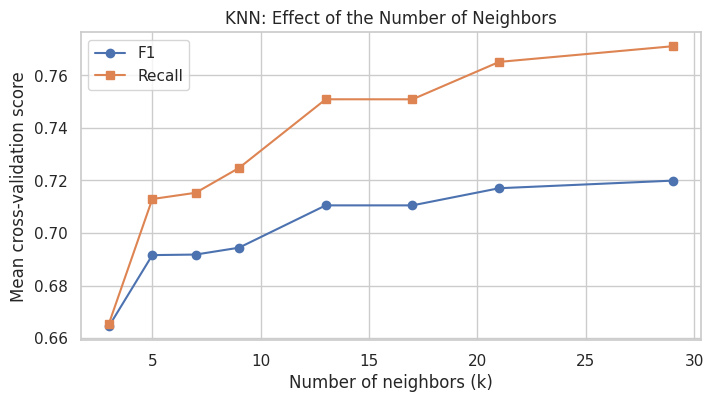

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(knn_cv_results["k"], knn_cv_results["mean_f1"], marker="o", label="F1")
plt.plot(knn_cv_results["k"], knn_cv_results["mean_recall"], marker="s", label="Recall")
plt.xlabel("Number of neighbors (k)")
plt.ylabel("Mean cross-validation score")
plt.title("KNN: Effect of the Number of Neighbors")
plt.legend()
plt.show()

### Exercise 2 — Choose k

Use the cross-validation results to answer:

1. Which `k` produced the highest mean F1-score?
2. Which `k` produced the highest mean recall?
3. Do these values identify the same model?
4. If missing a high-risk order is expensive, which metric should influence your decision?

Do not choose a value using the test set.

## 10. Uniform versus distance weighting

With uniform weighting, each of the `k` neighbors contributes one vote. With distance weighting, a nearby observation contributes more than a farther observation.

Distance weighting can help when the closest examples are more informative than other observations inside the neighborhood. It is not guaranteed to improve performance, so we compare it empirically.

In [17]:
weight_rows = []

for weight in ["uniform", "distance"]:
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=11, weights=weight))
    ])
    scores = cross_validate(
        candidate, X_train, y_train, cv=cv,
        scoring={"f1": "f1", "recall": "recall", "precision": "precision"},
        n_jobs=-1
    )
    weight_rows.append({
        "weights": weight,
        "mean_f1": scores["test_f1"].mean(),
        "mean_recall": scores["test_recall"].mean(),
        "mean_precision": scores["test_precision"].mean()
    })

pd.DataFrame(weight_rows).round(3)

,weights,mean_f1,mean_recall,mean_precision
0,uniform,0.710,0.746,0.677
1,distance,0.712,0.747,0.680


## 11. KNN strengths and limitations

**Strengths**

- Simple to understand and explain.
- Can model irregular decision boundaries.
- Naturally supports multi-class classification.
- Has few assumptions about the shape of the data distribution.

**Limitations**

- Prediction can be slow when the training set is large.
- Requires meaningful distance measurements and careful scaling.
- Can be sensitive to irrelevant features and noisy observations.
- Performance often decreases in high-dimensional spaces (the curse of dimensionality).
- It stores training data, which can increase memory use.

KNN is often a useful baseline, especially when the dataset is not too large and local similarity is meaningful.

# Part B — Support Vector Machines (SVM)

## 12. SVM intuition

A Support Vector Machine is a supervised learning algorithm that can be used for classification and regression. In classification, it seeks a decision boundary that separates classes.

For a linear SVM, many separating boundaries may classify the training data correctly. SVM prefers the boundary with the largest margin: the distance between the boundary and the closest training observations from each class.

The closest observations that define this margin are called **support vectors**.

### Why maximize the margin?

A wider margin can improve the model's ability to generalize to unseen data. The final result also depends on the regularization setting and the structure of the dataset.

## 13. The decision boundary and margin

For a linear classifier, a decision boundary can be represented as:

\[
w^T x + b = 0
\]

The prediction depends on which side of the boundary an observation falls.

The margin is related to the distance between the boundary and the closest training points. SVM chooses a boundary that balances a wide margin with classification errors.

In real datasets, classes may overlap. A **soft-margin SVM** allows some observations to be inside the margin or incorrectly classified.

## 14. The role of C

`C` controls the trade-off between a wider margin and training errors.

- **Smaller C:** stronger regularization. The model accepts more training violations in exchange for a wider, smoother margin.
- **Larger C:** weaker regularization. The model places more emphasis on classifying training examples correctly, which can create a more complex boundary.

The best value is data-dependent and should be selected with cross-validation.

In [18]:
c_values = [0.01, 0.1, 1, 10, 100]
c_rows = []

for c_value in c_values:
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=c_value))
    ])
    scores = cross_validate(
        candidate, X_train, y_train, cv=cv,
        scoring={"f1": "f1", "recall": "recall"},
        n_jobs=-1
    )
    c_rows.append({
        "C": c_value,
        "mean_f1": scores["test_f1"].mean(),
        "mean_recall": scores["test_recall"].mean()
    })

pd.DataFrame(c_rows).round(3)

,C,mean_f1,mean_recall
0,0.01,0.744,0.817
1,0.10,0.736,0.782
2,1.00,0.734,0.778
3,10.00,0.734,0.778
4,100.00,0.734,0.778


## 15. Linear and non-linear SVM

A linear SVM uses a straight decision boundary in the feature space.

Some classification problems cannot be separated well with a straight line or hyperplane. SVM can use **kernels** to represent more flexible boundaries without explicitly creating every transformed feature.

Common kernels:

- `linear`: linear decision boundary.
- `rbf`: radial basis function; can create flexible non-linear boundaries.
- `poly`: polynomial decision boundary.

The RBF kernel is a common starting point when a non-linear relationship is plausible.

## 16. Understand the RBF kernel and gamma

The RBF kernel measures similarity between observations. Its influence is controlled by `gamma`.

- **Low gamma:** each training point has a broader influence; the boundary is smoother.
- **High gamma:** each training point has a more local influence; the boundary can become highly detailed.

A very high gamma may fit noise. A very low gamma may fail to capture useful structure.

For an RBF SVM, both `C` and `gamma` should be considered during model selection.

In [19]:
svm_candidates = {
    "Linear SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=1))
    ]),
    "RBF SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1, gamma="scale"))
    ])
}

svm_cv_rows = []
for model_name, model in svm_candidates.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"accuracy": "accuracy", "precision": "precision",
                 "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"},
        n_jobs=-1
    )
    svm_cv_rows.append({
        "model": model_name,
        **{metric: scores[f"test_{metric}"].mean()
           for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]}
    })

pd.DataFrame(svm_cv_rows).round(3)

,model,accuracy,precision,recall,f1,roc_auc
0,Linear SVM,0.669,0.694,0.778,0.734,0.713
1,RBF SVM,0.655,0.671,0.805,0.732,0.684


## 17. Fit an RBF SVM and inspect support vectors

The fitted SVM exposes the support vectors through `support_vectors_`. These are the training observations that contribute to the decision boundary.

The number of support vectors is not a direct measure of model quality. It helps us understand how much of the training data defines the classifier.

In [20]:
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])
rbf_svm.fit(X_train, y_train)

fitted_svc = rbf_svm.named_steps["svm"]
print("Number of support vectors:", fitted_svc.n_support_)
print("Total support vectors:", fitted_svc.support_vectors_.shape[0])
print("Training observations:", len(X_train))

Number of support vectors: [510 564]
Total support vectors: 1074
Training observations: 1440


## 18. SVM scores and probability estimates

By default, `SVC` produces class predictions and decision scores. It does not provide probability estimates by default.

The `decision_function` returns a score related to the distance from the decision boundary. It is useful for ranking observations, but it should not be interpreted as a calibrated probability.

If a business workflow requires probabilities, probability calibration can be applied using a suitable calibration method. Calibration must be fitted without using the final test labels.

For this notebook, we use decision scores for ROC-AUC and focus on class predictions for the primary model comparison.

In [21]:
svm_decision_scores = rbf_svm.decision_function(X_test)
print("First 10 decision scores:")
print(np.round(svm_decision_scores[:10], 3))

First 10 decision scores:
[ 0.896 -0.353  0.218 -0.667 -0.352  1.174  0.038  1.142  1.054  0.618]


## 19. Compare kernel choices

The following experiment compares linear, RBF, and polynomial kernels. All models are scaled inside their pipelines.

In [22]:
kernel_rows = []

for kernel_name, kernel_params in [
    ("linear", {}),
    ("rbf", {"gamma": "scale"}),
    ("poly", {"degree": 2, "gamma": "scale"})
]:
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel=kernel_name, C=1.0, **kernel_params))
    ])
    scores = cross_validate(
        candidate, X_train, y_train, cv=cv,
        scoring={"f1": "f1", "recall": "recall", "roc_auc": "roc_auc"},
        n_jobs=-1
    )
    kernel_rows.append({
        "kernel": kernel_name,
        "mean_f1": scores["test_f1"].mean(),
        "mean_recall": scores["test_recall"].mean(),
        "mean_roc_auc": scores["test_roc_auc"].mean()
    })

pd.DataFrame(kernel_rows).round(3)

,kernel,mean_f1,mean_recall,mean_roc_auc
0,linear,0.734,0.778,0.713
1,rbf,0.732,0.805,0.684
2,poly,0.739,1.000,0.532


## 20. Tune an RBF SVM with cross-validation

We use `GridSearchCV` to compare a focused set of `C` and `gamma` values. The scaler is part of the pipeline, so it is fitted separately within each training fold.

The selection metric is F1-score. In a real deployment, the scoring metric should reflect the relative business cost of false positives and false negatives.

In [23]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

svm_param_grid = {
    "svm__C": [0.1, 1, 10, 50],
    "svm__gamma": ["scale", 0.01, 0.1, 1]
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)
svm_search.fit(X_train, y_train)

print("Best parameters:", svm_search.best_params_)
print(f"Best mean CV F1: {svm_search.best_score_:.3f}")

Best parameters: {'svm__C': 0.1, 'svm__gamma': 'scale'}
Best mean CV F1: 0.752


In [24]:
svm_grid_results = pd.DataFrame(svm_search.cv_results_)
svm_grid_results[
    ["param_svm__C", "param_svm__gamma", "mean_test_score", "rank_test_score"]
].sort_values("rank_test_score").head(10)

,param_svm__C,param_svm__gamma,mean_test_score,rank_test_score
0,0.1,scale,0.751976,1
2,0.1,0.1,0.749419,2
5,1.0,0.01,0.742788,3
9,10.0,0.01,0.740746,4
13,50.0,0.01,0.738659,5
1,0.1,0.01,0.738593,6
3,0.1,1,0.738501,7
6,1.0,0.1,0.732613,8
4,1.0,scale,0.731650,9
7,1.0,1,0.729219,10


### Exercise 3 — Interpret SVM tuning

1. Which combination of `C` and `gamma` achieved the best cross-validation F1-score?
2. What could happen if `C` is extremely large?
3. What could happen if `gamma` is extremely large?
4. Why is scaling included inside the pipeline rather than performed once before cross-validation?

Explain each answer in your own words.

# Part C — Model Evaluation and Selection

## 21. Build a consistent comparison

We now compare KNN and SVM using the same training and test partitions. KNN is tuned with a small grid over `k` and weighting. The RBF SVM uses the best settings found by cross-validation.

The test set is used only after the training-stage selection is complete.

In [25]:
knn_param_grid = {
    "knn__n_neighbors": [5, 7, 9, 11, 15, 21],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

knn_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ]),
    param_grid=knn_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)
knn_search.fit(X_train, y_train)

print("Best KNN parameters:", knn_search.best_params_)
print(f"Best KNN mean CV F1: {knn_search.best_score_:.3f}")

Best KNN parameters: {'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'uniform'}
Best KNN mean CV F1: 0.723


## 22. Evaluate the selected models on the test set

We report accuracy, precision, recall, F1-score, and ROC-AUC. For KNN, `predict_proba` provides class probabilities. For SVC, the decision function is used for ROC-AUC.

Remember: the numerical results are specific to this synthetic dataset and should not be treated as real business benchmarks.

In [26]:
best_knn = knn_search.best_estimator_
best_svm = svm_search.best_estimator_

knn_test_pred = best_knn.predict(X_test)
svm_test_pred = best_svm.predict(X_test)

knn_test_prob = best_knn.predict_proba(X_test)[:, 1]
svm_test_score = best_svm.decision_function(X_test)

comparison = pd.DataFrame([
    {
        "model": "KNN",
        "accuracy": accuracy_score(y_test, knn_test_pred),
        "precision": precision_score(y_test, knn_test_pred, zero_division=0),
        "recall": recall_score(y_test, knn_test_pred, zero_division=0),
        "f1": f1_score(y_test, knn_test_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, knn_test_prob)
    },
    {
        "model": "RBF SVM",
        "accuracy": accuracy_score(y_test, svm_test_pred),
        "precision": precision_score(y_test, svm_test_pred, zero_division=0),
        "recall": recall_score(y_test, svm_test_pred, zero_division=0),
        "f1": f1_score(y_test, svm_test_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, svm_test_score)
    }
])

comparison.round(3)

,model,accuracy,precision,recall,f1,roc_auc
0,KNN,0.650,0.679,0.763,0.719,0.686
1,RBF SVM,0.658,0.656,0.877,0.751,0.696


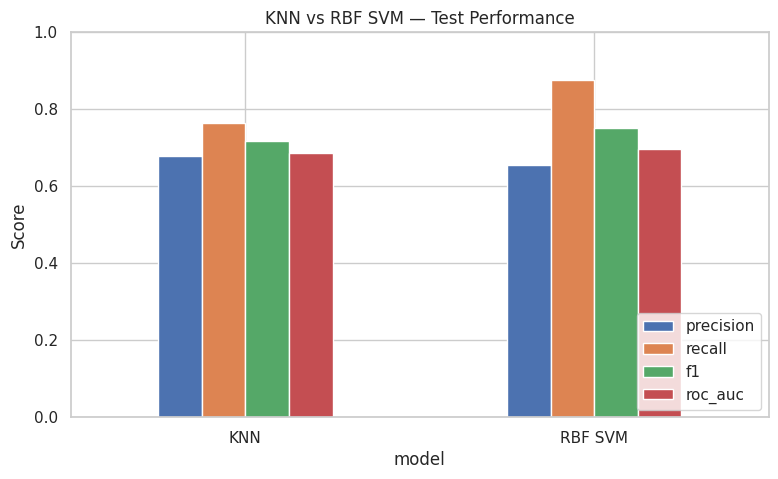

In [27]:
comparison.set_index("model")[["precision", "recall", "f1", "roc_auc"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("KNN vs RBF SVM — Test Performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## 23. Confusion matrices and error analysis

A confusion matrix helps us see the types of errors made by each model:

- **True positive:** a high-risk order correctly identified.
- **False positive:** a standard-risk order incorrectly flagged as high risk.
- **True negative:** a standard-risk order correctly identified.
- **False negative:** a high-risk order missed by the model.

In this business case, false negatives may allow preventable returns to pass without intervention. False positives consume review capacity. The preferred balance depends on the cost of each outcome.

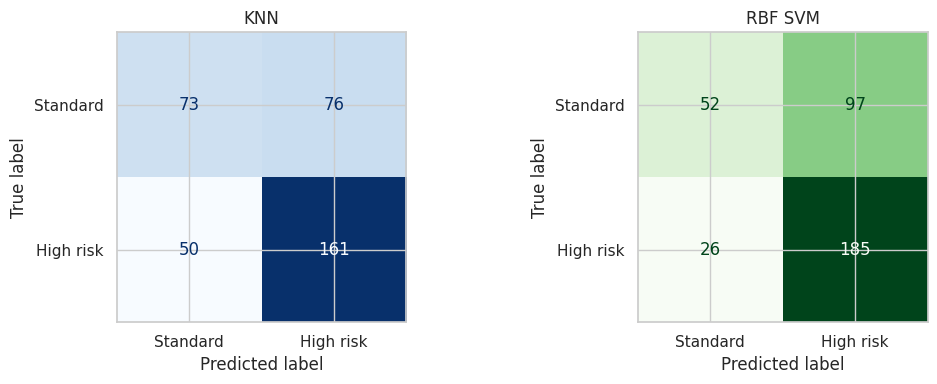

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_test_pred,
    display_labels=["Standard", "High risk"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("KNN")

ConfusionMatrixDisplay.from_predictions(
    y_test, svm_test_pred,
    display_labels=["Standard", "High risk"],
    cmap="Greens", ax=axes[1], colorbar=False
)
axes[1].set_title("RBF SVM")

plt.tight_layout()
plt.show()

## 24. ROC curves

The ROC curve shows the relationship between the true positive rate and false positive rate across classification thresholds.

ROC-AUC summarizes ranking performance across thresholds. A higher value generally indicates better separation between the two classes, but it does not identify the best operational threshold by itself.

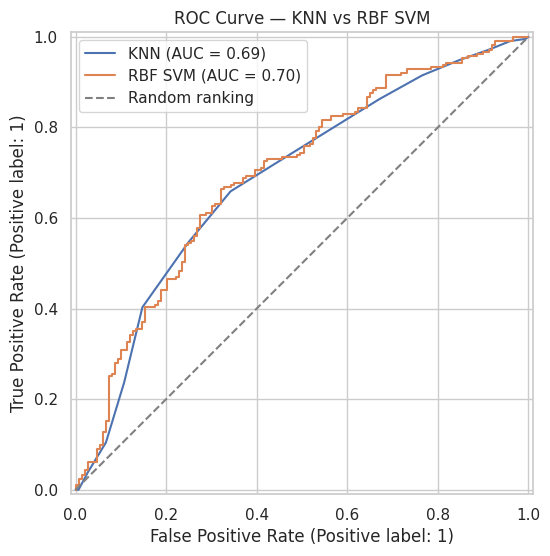

In [29]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(
    y_test, knn_test_prob, name="KNN", ax=ax
)
RocCurveDisplay.from_predictions(
    y_test, svm_test_score, name="RBF SVM", ax=ax
)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random ranking")
ax.set_title("ROC Curve — KNN vs RBF SVM")
ax.legend()
plt.show()

## 25. Compare the algorithms beyond the score

| Consideration | KNN | SVM |
|---|---|---|
| Main idea | Nearby examples vote | Maximum-margin boundary |
| Scaling | Usually essential | Usually essential |
| Training cost | Often relatively low | Can be high, especially with RBF |
| Prediction cost | Can be high as data grows | Depends on support vectors and kernel |
| Non-linear patterns | Flexible local boundaries | Non-linear kernels |
| Key settings | `k`, `weights`, `metric` | `C`, `kernel`, `gamma` |
| Interpretability | Neighbor-based explanation | Margin and support-vector concepts |

Neither algorithm is always better. Selection should consider validation performance, prediction time, dataset size, feature dimensions, interpretability, and business constraints.

## 26. Common mistakes to avoid

1. **Skipping feature scaling:** distance and margin calculations can be dominated by large-scale features.
2. **Scaling before splitting:** this allows information from the test set to influence preprocessing.
3. **Tuning on the test set:** this makes the test score less independent.
4. **Using accuracy alone:** it can hide poor performance on the high-risk class.
5. **Assuming a larger `k` is always better:** the effect depends on the dataset.
6. **Assuming a complex kernel is always better:** a flexible boundary can overfit.
7. **Treating SVM decision scores as probabilities:** they are not calibrated probabilities.
8. **Ignoring prediction cost:** KNN and kernel SVM may become expensive as the dataset grows.

# Part D — Applied Mini Project

## 27. Mini project: AdventureWorks Return-Risk Model Selection

### Business brief

The Operations Manager wants a recommendation for a model that can flag high-risk orders before dispatch. The team needs a model that identifies a useful share of risky orders without sending too many standard orders for manual review.

### Your tasks

1. Inspect the dataset and describe the target distribution.
2. Split the data into training and test sets using stratification.
3. Build a scaled KNN pipeline.
4. Compare at least five values of `k`.
5. Build a linear SVM and an RBF SVM.
6. Tune the RBF SVM using cross-validation.
7. Compare the selected KNN and SVM on the held-out test set.
8. Review confusion matrices, recall, precision, F1-score, and ROC-AUC.
9. Recommend one model and explain the trade-offs.
10. State two limitations of this experiment and one next step before deployment.

### Deliverable

Prepare a short model-selection report with:

- Business objective
- Data and validation approach
- Models and parameter settings
- Evaluation results
- Error analysis
- Final recommendation
- Limitations and next steps

Use the next cells to complete the project.

In [30]:
# Mini Project — Step 1: Inspect the target and features

# TODO:
# 1. Display the shape of X and the class distribution of y.
# 2. Check whether there are missing values.
# 3. Display summary statistics for the features.

In [31]:
# Mini Project — Step 2: Create a stratified train/test split

# TODO:
# Use train_test_split with test_size=0.20, random_state=42, and stratify=y.

In [32]:
# Mini Project — Step 3: Build and evaluate a KNN pipeline

# TODO:
# 1. Create a Pipeline with StandardScaler and KNeighborsClassifier.
# 2. Use cross-validation to compare k = 3, 5, 7, 9, 13.
# 3. Select a value using F1-score.

In [33]:
# Mini Project — Step 4: Build and tune an RBF SVM

# TODO:
# 1. Create a Pipeline with StandardScaler and SVC(kernel="rbf").
# 2. Tune C and gamma with GridSearchCV.
# 3. Use stratified cross-validation and F1-score.

In [34]:
# Mini Project — Step 5: Final comparison

# TODO:
# 1. Evaluate the selected KNN and SVM on the test set.
# 2. Report precision, recall, F1-score, and ROC-AUC.
# 3. Plot both confusion matrices.
# 4. Write a short recommendation.

## 28. Knowledge check

**1. Why is feature scaling important for KNN?**

A. It increases the number of training records.  
B. It prevents large-scale features from dominating distance calculations.  
C. It removes the need for a test set.  
D. It guarantees higher accuracy.

**2. What does `k` represent in KNN?**

A. Number of features.  
B. Number of classes.  
C. Number of nearest training observations used to vote.  
D. Number of cross-validation folds.

**3. What is a support vector?**

A. Any observation in the test set.  
B. A training observation that helps define the SVM decision boundary.  
C. A feature scaling method.  
D. A type of distance metric.

**4. What is the general effect of increasing `C` in SVM?**

A. Stronger regularization and a wider tolerance for training errors.  
B. Greater emphasis on classifying training observations correctly.  
C. Fewer input features.  
D. Automatic feature scaling.

**5. What does a high RBF `gamma` generally do?**

A. Makes each training point's influence more local.  
B. Removes the kernel.  
C. Guarantees a linear boundary.  
D. Prevents overfitting in every case.

**6. Why should scaling be inside a cross-validation pipeline?**

A. To make the notebook shorter.  
B. To fit preprocessing only on each fold's training portion.  
C. To use the test set during training.  
D. To remove the target variable.

## 29. Knowledge check — Answer key

1. **B** — scaling prevents features with large numerical ranges from dominating distance calculations.
2. **C** — `k` is the number of nearest training observations used in the vote.
3. **B** — support vectors are the training observations that help define the margin and decision boundary.
4. **B** — a larger `C` penalizes training violations more strongly and may lead to a more complex boundary.
5. **A** — a higher `gamma` gives each training point a more local influence.
6. **B** — the pipeline prevents preprocessing leakage by fitting the scaler separately inside each training fold.

## 30. Instructor reference — Distance exercise

For Order A `[0.20, 0.40, 0.10]` and Order B `[0.50, 0.10, 0.30]`:

- Difference: `[-0.30, 0.30, -0.20]`
- Euclidean distance: `sqrt(0.09 + 0.09 + 0.04) = sqrt(0.22) ≈ 0.469`
- Manhattan distance: `0.30 + 0.30 + 0.20 = 0.80`

The two measures aggregate feature differences in different ways.

## 31. Key takeaways

- KNN predicts from nearby training observations. Its results depend on the distance metric, `k`, weighting, and feature scaling.
- SVM learns a decision boundary by balancing margin size and classification errors.
- The `C` parameter controls the regularization trade-off. For RBF SVM, `gamma` controls how local the influence of training observations is.
- Scaling should be included in the model pipeline for both algorithms in this dataset.
- Cross-validation supports model selection; the held-out test set supports final evaluation.
- The best model is the one that fits the business objective and operational constraints, not necessarily the one with the highest single metric.

### Readiness checklist

Before moving to the next topic, make sure you can:

- [ ] Explain how KNN assigns a class to a new observation.
- [ ] Explain Euclidean and Manhattan distance.
- [ ] Explain why scaling matters and how a pipeline prevents leakage.
- [ ] Describe the purpose of `k` and `weights`.
- [ ] Explain a decision boundary, margin, and support vectors.
- [ ] Describe the effects of `C` and `gamma`.
- [ ] Compare linear and RBF kernels.
- [ ] Evaluate models using cross-validation and a separate test set.
- [ ] Explain why model selection must consider business costs.

### Further reading

- [scikit-learn — Nearest Neighbors](https://scikit-learn.org/stable/modules/neighbors.html)
- [scikit-learn — KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)
- [scikit-learn — Support Vector Machines](https://scikit-learn.org/stable/modules/svm.html)
- [scikit-learn — SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
- [scikit-learn — Importance of Feature Scaling](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)